In [37]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [38]:
# 구글 API에서 제공하는 Fashion MNIST 데이터셋 다운로드
(trainX, trainY), (testX, testY) = tf.keras.datasets.fashion_mnist.load_data()

# 이 이미지의 정체를 확인하기
# plt.imshow(trainX[0], cmap='gray')
# plt.show()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [39]:
# 데이터 정규화를 위해 0-255(uint8)값을 0~1 사이의 값으로 변환
trainX = trainX / 255.0 
testX = testX / 255.0

# 정규화 데이터 확인용
# trainX[0]
# plt.imshow(trainX[0], cmap='gray')
# plt.show()

In [ ]:
# 모델 빌드
myModel = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),  # flatten으로 찌그러뜨리기(1차원화)
    tf.keras.layers.Dense(128, activation='relu'),   # 음수 0으로 처리해주세요
    tf.keras.layers.Dense(10, activation='softmax')   # 출력층, 10개의 클래스로로
])
# 모델 컴파일
myModel.compile(optimizer='adam',
                          loss='sparse_categorical_crossentropy', # 다중 클래스 분류
                          metrics=['accuracy'])     # 평가지표: 정확도

In [41]:
myHistory = myModel.fit(trainX, trainY, epochs=10, validation_split=0.2) 

Epoch 1/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.5127 - accuracy: 0.8206 - val_loss: 0.4263 - val_accuracy: 0.8486
Epoch 2/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.3837 - accuracy: 0.8608 - val_loss: 0.3777 - val_accuracy: 0.8657
Epoch 3/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.3437 - accuracy: 0.8750 - val_loss: 0.3824 - val_accuracy: 0.8572
Epoch 4/10
1500/1500 [==============================] - 2s 2ms/step - loss: 0.3171 - accuracy: 0.8834 - val_loss: 0.3466 - val_accuracy: 0.8750
Epoch 5/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.3003 - accuracy: 0.8892 - val_loss: 0.3384 - val_accuracy: 0.8761
Epoch 6/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.2849 - accuracy: 0.8951 - val_loss: 0.3354 - val_accuracy: 0.8770
Epoch 7/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.2698 - accuracy: 0.8994 - val_loss: 0.3139 - val_accuracy:

In [ ]:
# 모델 평가
myPredict = myModel.predict(testX)[0]
myPredict

313/313 [==============================] - 1s 1ms/step


array([5.98489976e-07, 3.62713735e-08, 2.98446103e-08, 2.26428587e-09,
       8.79039760e-07, 1.67375442e-03, 9.53511858e-07, 1.22241024e-02,
       1.20141385e-05, 9.86087620e-01], dtype=float32)

<BarContainer object of 10 artists>

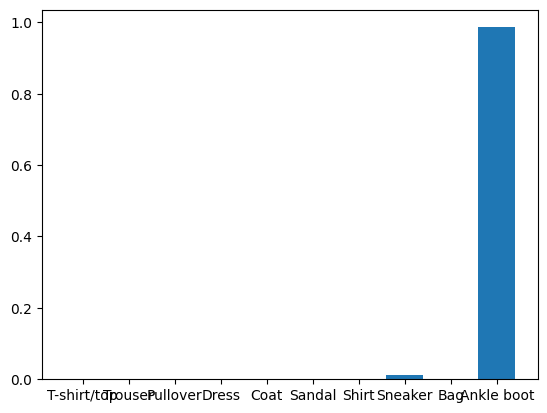

In [43]:
plt.bar(class_names, myPredict)

In [45]:
# 예측이 틀린 인덱스를 찾아보자.
import numpy as np

myPredict = myModel.predict(testX)
myPredictedLabel = np.argmax(myPredict, axis=1)

# 예측한 레이블과 실제 레이블 비교
wrongIndex = np.where(myPredictedLabel != testY)
wrongIndex

313/313 [==============================] - 1s 2ms/step


(array([  12,   17,   23, ..., 9972, 9977, 9985], dtype=int64),)

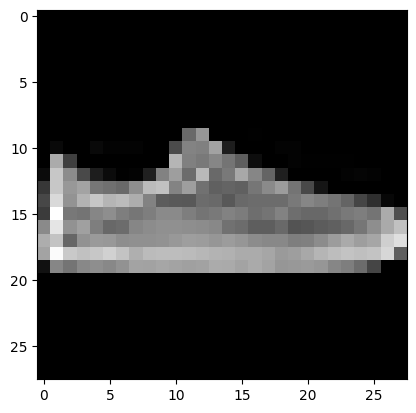

In [46]:
# 12번 인덱스 사진 확인하기
plt.imshow(testX[12], cmap='gray')

313/313 [==============================] - 1s 2ms/step


<BarContainer object of 10 artists>

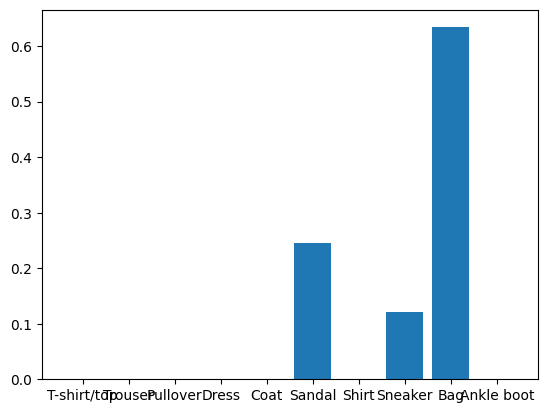

In [49]:
myPredict_12 = myModel.predict(testX)[12]
plt.bar(class_names, myPredict_12)